In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# 设置随机种子
torch.manual_(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("当前使用的设备:", device)

# 自定义 Dataset
class DrugResponseDataset(Dataset):
    def __init__(self, df, y_mean=None, y_std=None):
        cell_cols = [c for c in df.columns if c.startswith(('PCA_', 'MUT_', 'MGMT_'))]
        self.cell_cols = cell_cols
        self.fingerprints = torch.tensor(
            np.stack(df['Morgan_FP'].values), dtype=torch.float32)
        self.cell_features = torch.tensor(
            df[cell_cols].values.astype(np.float32), dtype=torch.float32)

        y = df['LN_IC50'].values.astype(np.float32)
        if y_mean is None:  # 训练集：计算并记录
            y_mean, y_std = float(y.mean()), float(y.std())
        self.y_mean, self.y_std = y_mean, y_std
        self.labels = torch.tensor((y - y_mean) / y_std, dtype=torch.float32)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.fingerprints[idx], self.cell_features[idx], self.labels[idx]

trainval_df = pd.read_pickle('train_random.pkl')   # 4085 行，80%
test_df     = pd.read_pickle('test_random.pkl')    # 1022 行，20%

train_df, val_df = train_test_split(trainval_df, test_size=0.15, random_state=42,stratify=trainval_df['ModelID'])   # 按细胞系分层，保证 val 也有所有 24 个细胞系

print(f"train={len(train_df)}, val={len(val_df)}, test={len(test_df)}")

train_ds = DrugResponseDataset(train_df)
val_ds   = DrugResponseDataset(val_df, train_ds.y_mean, train_ds.y_std)
test_ds  = DrugResponseDataset(test_df, train_ds.y_mean, train_ds.y_std)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False)

print(f"cell_dim = {len(train_ds.cell_cols)}")

当前使用的设备: cpu
train=3472, val=613, test=1022
cell_dim = 44


In [11]:
class BaselineMLP(nn.Module):
    def __init__(self, fp_dim=2048, cell_dim=256, hidden_dim=256):
        super(BaselineMLP, self).__init__()
        # 药物塔 (指纹)
        self.drug_net = nn.Sequential(
            nn.Linear(fp_dim, 512),
            nn.ReLU(),
            nn.Dropout(0.3), # ★ 强正则化防过拟合
            nn.Linear(512, hidden_dim)
        )
        # 细胞系塔 (PCA降维后的特征)
        self.cell_net = nn.Sequential(
            nn.Linear(cell_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.3), # ★ 强正则化防过拟合
            nn.Linear(128, hidden_dim)
        )
        # 融合预测层
        self.predictor = nn.Sequential(
            nn.Linear(hidden_dim * 2, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, fp, cell):
        drug_emb = self.drug_net(fp)
        cell_emb = self.cell_net(cell)
        combined = torch.cat([drug_emb, cell_emb], dim=1)
        return self.predictor(combined).squeeze()

# ★ 获取实际的数据维度
sample_fp, sample_cell, sample_label = train_dataset[0]
actual_cell_dim = sample_cell.shape[0]
print(f"检测到实际细胞系特征维度: {actual_cell_dim}")

# 将真实维度传入模型
model = BaselineMLP(cell_dim=actual_cell_dim).to(device)
print(model)

检测到实际细胞系特征维度: 23
BaselineMLP(
  (drug_net): Sequential(
    (0): Linear(in_features=2048, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
  )
  (cell_net): Sequential(
    (0): Linear(in_features=23, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=256, bias=True)
  )
  (predictor): Sequential(
    (0): Linear(in_features=512, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [16]:
# 根据数据集的实际维度重新初始化模型，解决维度不匹配 (44 vs 23) 的问题
actual_cell_dim = train_ds.cell_features.shape[1]
model = BaselineMLP(cell_dim=actual_cell_dim).to(device)

criterion = nn.MSELoss()
# weight_decay 是 L2 正则化，进一步防过拟合
optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)

def evaluate(model, dataloader, y_mean, y_std):
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for fp, cell, label in dataloader:
            fp, cell = fp.to(device), cell.to(device)
            out = model(fp, cell).cpu().numpy()
            preds.extend(out)
            trues.extend(label.cpu().numpy())
    preds = np.array(preds) * y_std + y_mean   # 反标准化
    trues = np.array(trues) * y_std + y_mean
    rmse = float(np.sqrt(np.mean((preds - trues) ** 2)))
    sp = float(spearmanr(preds, trues).correlation)
    return rmse, sp, preds, trues

best_val_rmse = float('inf')
patience_counter = 0
patience = 15

for epoch in range(100):
    model.train()
    for fp, cell, y in train_loader:
        fp, cell, y = fp.to(device), cell.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(fp, cell), y)
        loss.backward()
        optimizer.step()

    val_rmse, val_sp, _, _ = evaluate(model, val_loader, train_ds.y_mean, train_ds.y_std)
    print(f"Epoch {epoch+1:03d} | Val RMSE: {val_rmse:.4f} | Val Spearman: {val_sp:.4f}")

    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        patience_counter = 0
        torch.save({
            'model_state': model.state_dict(),
            'y_mean': train_ds.y_mean,
            'y_std':  train_ds.y_std,
            'cell_cols': train_ds.cell_cols,
        }, 'best_fp_random.pt')
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"早停 @ Epoch {epoch+1}")
            break

# ===== 最后，test 只评估一次 =====
# 修改此处：从保存的字典中提取 'model_state'
model.load_state_dict(torch.load('best_fp_random.pt')['model_state'])
test_rmse, test_sp, test_preds, test_trues = evaluate(
    model, test_loader, train_ds.y_mean, train_ds.y_std)
print(f"\n★ 最终 Test RMSE: {test_rmse:.4f} | Test Spearman: {test_sp:.4f}")

Epoch 001 | Val RMSE: 3.5062 | Val Spearman: 0.0796
Epoch 002 | Val RMSE: 3.5477 | Val Spearman: 0.0316
Epoch 003 | Val RMSE: 2.8912 | Val Spearman: 0.0780
Epoch 004 | Val RMSE: 2.9928 | Val Spearman: 0.0686
Epoch 005 | Val RMSE: 2.8468 | Val Spearman: 0.0752
Epoch 006 | Val RMSE: 2.8163 | Val Spearman: 0.1609
Epoch 007 | Val RMSE: 2.8083 | Val Spearman: 0.1981
Epoch 008 | Val RMSE: 2.8007 | Val Spearman: 0.1929
Epoch 009 | Val RMSE: 2.7687 | Val Spearman: 0.2946
Epoch 010 | Val RMSE: 2.7522 | Val Spearman: 0.3734
Epoch 011 | Val RMSE: 2.7274 | Val Spearman: 0.4507
Epoch 012 | Val RMSE: 2.7017 | Val Spearman: 0.4165
Epoch 013 | Val RMSE: 2.6168 | Val Spearman: 0.4969
Epoch 014 | Val RMSE: 2.4615 | Val Spearman: 0.6091
Epoch 015 | Val RMSE: 2.3230 | Val Spearman: 0.6870
Epoch 016 | Val RMSE: 2.1002 | Val Spearman: 0.6912
Epoch 017 | Val RMSE: 1.9037 | Val Spearman: 0.7500
Epoch 018 | Val RMSE: 1.7740 | Val Spearman: 0.7611
Epoch 019 | Val RMSE: 1.7054 | Val Spearman: 0.7507
Epoch 020 | 

In [22]:
# ============================================================
# 诊断 1：Drug-only baseline
# 用训练集里每种药物的平均 IC50 预测测试集
# ============================================================

# 训练集每种药物的平均 IC50
drug_mean = train_df.groupby('DRUG_NAME')['LN_IC50'].mean()

# 在 test 上打预测
test_diag = test_df.copy()
test_diag['pred_drug'] = test_diag['DRUG_NAME'].map(drug_mean)

# 只保留 test 中出现过的药物（random split 下几乎全覆盖）
mask_drug = test_diag['pred_drug'].notna()
print(f"[Drug-only] test 中 {mask_drug.sum()}/{len(test_diag)} 条记录的药物在 train 出现过")

sp_drug_only = spearmanr(
    test_diag.loc[mask_drug, 'pred_drug'],
    test_diag.loc[mask_drug, 'LN_IC50']
).correlation
print(f"[Drug-only] Spearman = {sp_drug_only:.4f}")

[Drug-only] test 中 1022/1022 条记录的药物在 train 出现过
[Drug-only] Spearman = 0.8349


In [23]:
# ============================================================
# 诊断 2：Cell-only 和 Additive baseline
# Cell-only = 只用细胞系均值；Additive = drug mean + cell mean - global mean
# ============================================================
cell_mean   = train_df.groupby('ModelID')['LN_IC50'].mean()
global_mean = train_df['LN_IC50'].mean()

# Cell-only
test_diag['pred_cell'] = test_diag['ModelID'].map(cell_mean)
mask_cell = test_diag['pred_cell'].notna()
sp_cell_only = spearmanr(
    test_diag.loc[mask_cell, 'pred_cell'],
    test_diag.loc[mask_cell, 'LN_IC50']
).correlation
print(f"[Cell-only] Spearman = {sp_cell_only:.4f}")

# Additive（无交互项）
test_diag['pred_additive'] = (
    test_diag['DRUG_NAME'].map(drug_mean)
    + test_diag['ModelID'].map(cell_mean)
    - global_mean
)
mask_add = test_diag['pred_additive'].notna()
sp_additive = spearmanr(
    test_diag.loc[mask_add, 'pred_additive'],
    test_diag.loc[mask_add, 'LN_IC50']
).correlation
print(f"[Additive]   Spearman = {sp_additive:.4f}  "
      f"(drug-only={sp_drug_only:.4f}, cell-only={sp_cell_only:.4f})")

[Cell-only] Spearman = 0.2107
[Additive]   Spearman = 0.8752  (drug-only=0.8349, cell-only=0.2107)


In [24]:
# ============================================================
# 诊断 3：模型全局 Spearman vs Within-cell-line Spearman
# 需要 model / test_loader / train_ds 已存在
# ============================================================

# 兼容两种 Dataset：标签标准化 / 未标准化
y_mean = float(getattr(train_ds, 'y_mean', 0.0))
y_std  = float(getattr(train_ds, 'y_std',  1.0))

@torch.no_grad()
def predict_test(model, loader, y_mean, y_std):
    model.eval()
    preds, trues = [], []
    for fp, cell, label in loader:
        fp, cell = fp.to(next(model.parameters()).device), cell.to(next(model.parameters()).device)
        out = model(fp, cell).cpu().numpy().reshape(-1)
        preds.append(out)
        trues.append(label.cpu().numpy().reshape(-1))
    preds = np.concatenate(preds) * y_std + y_mean
    trues = np.concatenate(trues) * y_std + y_mean
    return preds, trues

test_preds, test_trues = predict_test(model, test_loader, y_mean, y_std)

# 顺序与 test_df 一致（shuffle=False）
assert len(test_preds) == len(test_df), \
    f"长度不一致: preds={len(test_preds)}, test_df={len(test_df)}"

# 全局 Spearman
sp_global = spearmanr(test_preds, test_trues).correlation
print(f"[Model] Global Spearman = {sp_global:.4f}")

# within-cell-line Spearman
def within_cell_spearman(preds, trues, cell_ids, min_n=20):
    df = pd.DataFrame({'pred': preds, 'true': trues, 'cell': cell_ids})
    sps = []
    for cell, g in df.groupby('cell'):
        if len(g) < min_n:
            continue
        sp = spearmanr(g['pred'], g['true']).correlation
        if not np.isnan(sp):
            sps.append(sp)
    return float(np.mean(sps)), float(np.std(sps)), len(sps)

sp_within_mean, sp_within_std, n_cells = within_cell_spearman(
    test_preds, test_trues, test_df['ModelID'].values
)
print(f"[Model] Within-cell Spearman = {sp_within_mean:.4f} ± {sp_within_std:.4f} "
      f"(n={n_cells} cells)")

[Model] Global Spearman = 0.8781
[Model] Within-cell Spearman = 0.8551 ± 0.0595 (n=24 cells)


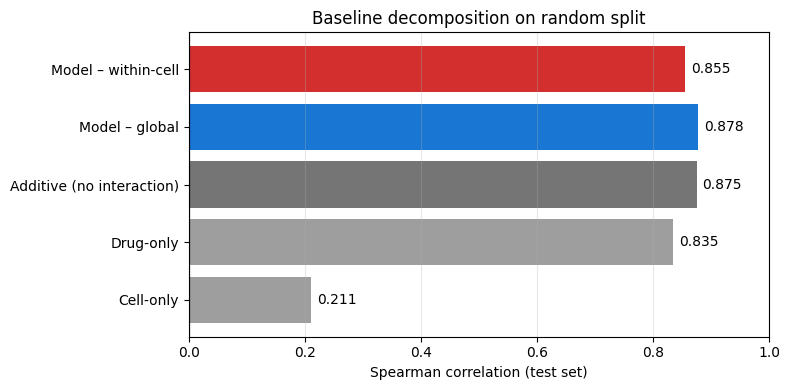


[汇总]
  Cell-only        = 0.2107
  Drug-only        = 0.8349
  Additive         = 0.8752
  Model global     = 0.8781
  Model within-cell= 0.8551 ± 0.0595


In [25]:
# ============================================================
# 诊断 4：把所有 baseline 拼成一张横向柱状图
# ============================================================
import matplotlib.pyplot as plt

labels = [
    'Cell-only',
    'Drug-only',
    'Additive (no interaction)',
    f'Model – global',
    f'Model – within-cell',
]
values = [sp_cell_only, sp_drug_only, sp_additive, sp_global, sp_within_mean]
colors = ['#9e9e9e', '#9e9e9e', '#757575', '#1976d2', '#d32f2f']

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(labels, values, color=colors)
ax.set_xlim(0, 1.0)
ax.set_xlabel('Spearman correlation (test set)')
ax.set_title('Baseline decomposition on random split')
ax.axvline(0, color='k', linewidth=0.8)
for bar, v in zip(bars, values):
    ax.text(v + 0.01, bar.get_y() + bar.get_height()/2,
            f'{v:.3f}', va='center', fontsize=10)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('diag_spearman_decomposition.png', dpi=150)
plt.show()

print("\n[汇总]")
print(f"  Cell-only        = {sp_cell_only:.4f}")
print(f"  Drug-only        = {sp_drug_only:.4f}")
print(f"  Additive         = {sp_additive:.4f}")
print(f"  Model global     = {sp_global:.4f}")
print(f"  Model within-cell= {sp_within_mean:.4f} ± {sp_within_std:.4f}")

In [26]:
# within-cell drug-only baseline：在细胞系内部用训练集药物均值预测
test_diag['pred_drug'] = test_diag['DRUG_NAME'].map(drug_mean)

def within_cell_spearman(preds, trues, cells, min_n=20):
    df = pd.DataFrame({'p': preds, 't': trues, 'c': cells})
    sps = [spearmanr(g['p'], g['t']).correlation
           for _, g in df.groupby('c') if len(g) >= min_n]
    sps = [s for s in sps if not np.isnan(s)]
    return np.mean(sps), np.std(sps), len(sps)

sp_do, sd_do, n = within_cell_spearman(
    test_diag['pred_drug'].values, test_diag['LN_IC50'].values, test_diag['ModelID'].values)
print(f"[within-cell] drug-only = {sp_do:.4f} ± {sd_do:.4f} (n={n})")
print(f"[within-cell] model     = {sp_within_mean:.4f} ± {sp_within_std:.4f}")

[within-cell] drug-only = 0.8554 ± 0.0598 (n=24)
[within-cell] model     = 0.8551 ± 0.0595
